# China: alternativas utilizables para el trabajo

Selección práctica de los huecos: series publicadas, estimaciones explícitas y alternativas parciales. La vista ampliada conserva todas las series originales. Las unidades y el significado se consultan en `seleccion_conceptos.csv`; el panel no tiene una unidad monetaria común. Las diferencias esenciales están en `discrepancias_informe.md`.

No se interpolan huecos, no se empalman fuentes y las subvenciones parciales no se usan para cerrar la identidad de rentas.

In [1]:
from pathlib import Path
import polars as pl
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image
ROOT=Path.cwd() if (Path.cwd()/'datos').exists() else Path.cwd().parent
OUT=ROOT/'output/revision_china/complecion'
FIG=OUT/'figuras';FIG.mkdir(exist_ok=True)
d=pl.read_parquet(ROOT/'datos/silver/china_completada.parquet')
selection=pl.read_csv(OUT/'seleccion_conceptos.csv',infer_schema_length=None)
display(selection.select('concept','selected_series','status','first','last','n','unit'))
def series(s):return d.filter(pl.col('series_id')==s).sort('year')
def show(fig,name):
    fig.tight_layout();p=FIG/(name+'.png');fig.savefig(p,dpi=130,bbox_inches='tight');plt.close(fig);display(Image(filename=str(p)))

/home/xylon/.config/matplotlib is not a writable directory
Matplotlib created a temporary cache directory at /tmp/matplotlib-yrmax5sr because there was an issue with the default path (/home/xylon/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


concept,selected_series,status,first,last,n,unit
str,str,str,i64,i64,i64,str
"""gdp_nominal""","""WDI.NY.GDP.MKTP.CN""","""CORRESPONDENCIA_CONCEPTUAL""",1960,2025,66,"""CNY_current"""
"""gdp_real""","""WDI.NY.GDP.MKTP.KN""","""CORRESPONDENCIA_CONCEPTUAL""",1960,2025,66,"""CNY_constant_provider_base"""
"""c_nominal""","""WDI.NE.CON.PRVT.CN""","""CORRESPONDENCIA_CONCEPTUAL""",1960,2024,65,"""CNY_current"""
"""c_real""","""INDEX.NA.q_c""","""INDICE_PWT_UTILIZABLE""",1952,2023,72,"""index_2008_100"""
"""g_nominal""","""WDI.NE.CON.GOVT.CN""","""CORRESPONDENCIA_CONCEPTUAL""",1960,2024,65,"""CNY_current"""
…,…,…,…,…,…,…
"""unemployment""","""ILO.UNE_2UNE_SEX_AGE_NB.XA:207…","""ALTERNATIVA_DOCUMENTADA""",1991,2025,35,"""thousand_persons"""
"""registered_unemployment""","""NBS.REGISTERED_UNEMPLOYED.URBA…","""ALTERNATIVA_NBS_COBERTURA_LIMI…",2020,2024,5,"""ten_thousand_persons"""
"""survey_unemployment""","""ILO.UNE_TUNE_SEX_AGE_NB.BA:160…","""ALTERNATIVA_DOCUMENTADA""",2016,2022,7,"""thousand_persons"""


## Rentas: aprovechar la serie publicada y mostrar la discrepancia

OCDE ofrece D1 e impuestos para 1992–2023 y excedente con renta mixta hasta 2021. La serie tributaria D2 coincide en 2023 con los **impuestos netos** NBS: la tratamos como neta solo como hipótesis de trabajo. Los componentes publicados no cierran exactamente con el PIB de la misma descarga. El residuo no se interpreta como subvenciones ni se usa para corregir las cifras.

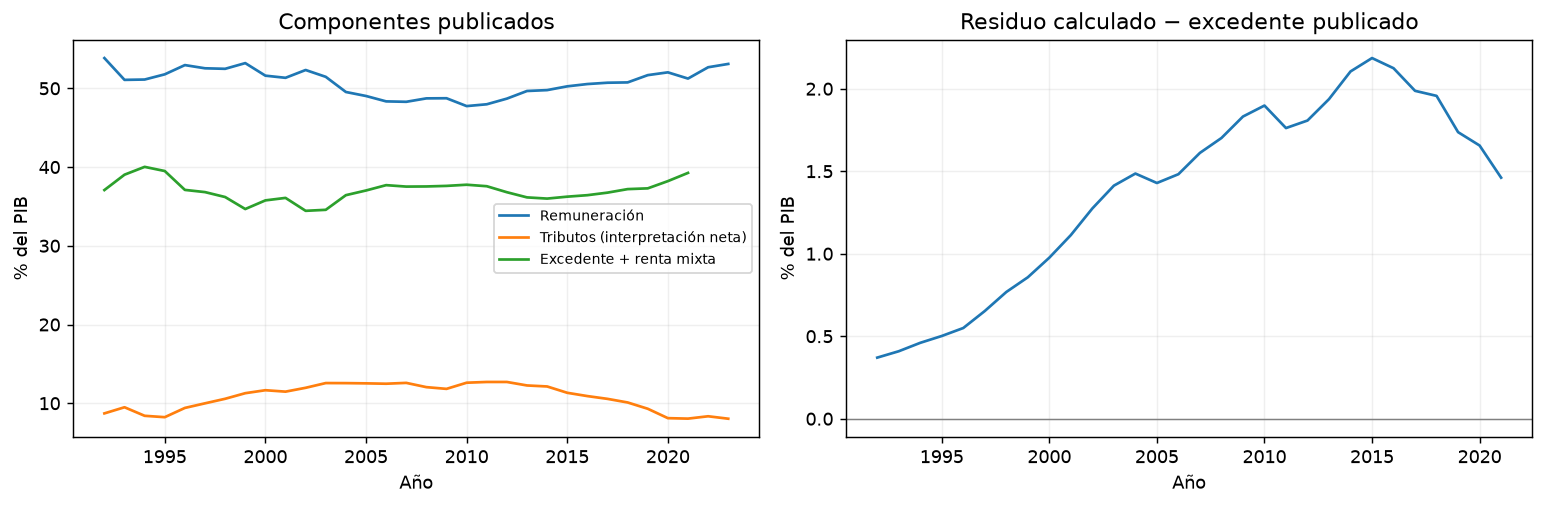

In [2]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
for s,label in [('D1','Remuneración'),('D2','Tributos (interpretación neta)'),('B2A3G','Excedente + renta mixta')]:
    z=series('SHARE.OECD.'+s);axes[0].plot(z['year'],z['value'],label=label)
axes[0].set(ylabel='% del PIB',xlabel='Año',title='Componentes publicados');axes[0].legend(fontsize=8)
gap=pl.read_csv(OUT/'rentas_discrepancia.csv')
axes[1].plot(gap['year'],gap['difference_percent_GDP']);axes[1].axhline(0,color='gray',lw=.8)
axes[1].set(ylabel='% del PIB',xlabel='Año',title='Residuo calculado − excedente publicado')
for ax in axes:ax.grid(alpha=.2)
show(fig,'01_rentas')

## CCF: una aproximación económica explícita

Se divide el consumo nominal de capital de cada grupo de activos por su índice de precios del stock y se suman los cuatro grupos. El resultado se expresa como índice 2021=100. Los precios del stock no son un deflactor específico de CCF; repetimos el cálculo con los precios de inversión para mostrar sensibilidad. No se presenta como CCF oficial de China ni como nivel comparable con AMECO.

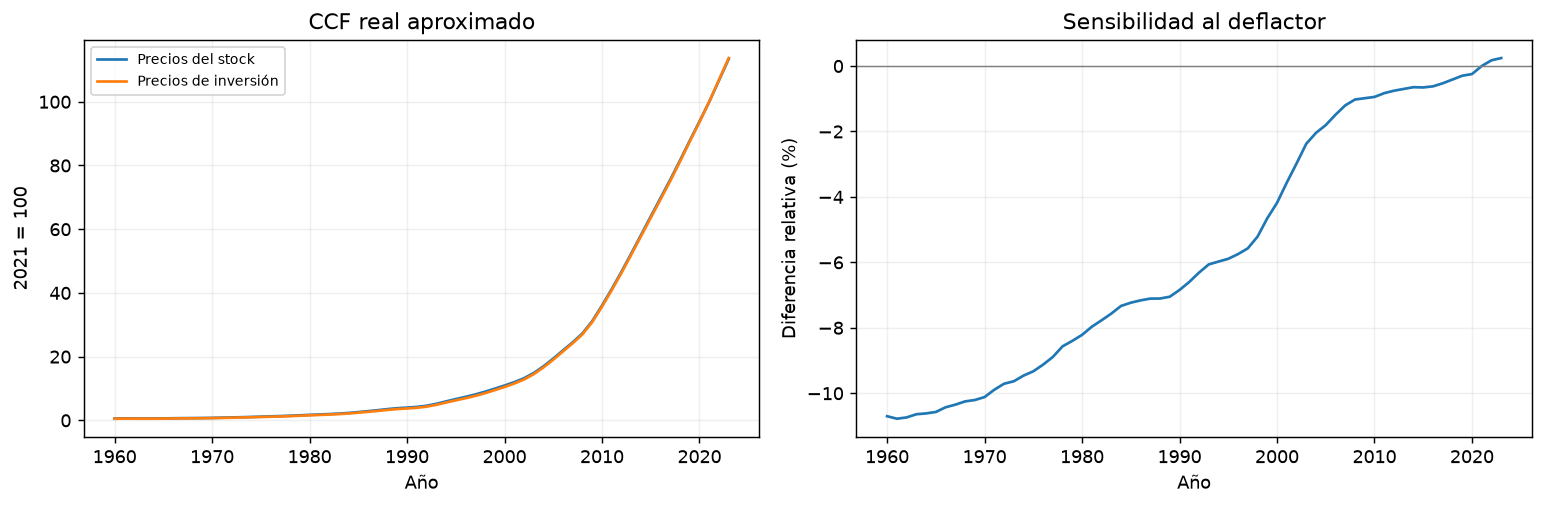

In [3]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
for sid,label in [('ALT.CCF_REAL_INDEX_NP','Precios del stock'),('ALT.CCF_REAL_INDEX_IP','Precios de inversión')]:
    z=series(sid).filter(pl.col('year')>=1960);axes[0].plot(z['year'],z['value'],label=label)
axes[0].set(ylabel='2021 = 100',xlabel='Año',title='CCF real aproximado');axes[0].legend(fontsize=8)
c=pl.read_csv(OUT/'ccf_calculo_y_sensibilidad.csv').filter(pl.col('year')>=1960)
axes[1].plot(c['year'],c['sensitivity_percent']);axes[1].axhline(0,color='gray',lw=.8)
axes[1].set(ylabel='Diferencia relativa (%)',xlabel='Año',title='Sensibilidad al deflactor')
for ax in axes:ax.grid(alpha=.2)
show(fig,'02_ccf')

## Existencias: dos preguntas, dos medidas

El índice FMI/IFS describe la evolución de un flujo real, con alcance P53 pendiente. El cociente nominal OCDE muestra el peso de P52+P53 en el PIB. Los dos se mantienen separados. Las existencias son un flujo que puede cambiar de signo; no conviene aplicar automáticamente logaritmos o interpretar el índice como stock almacenado.

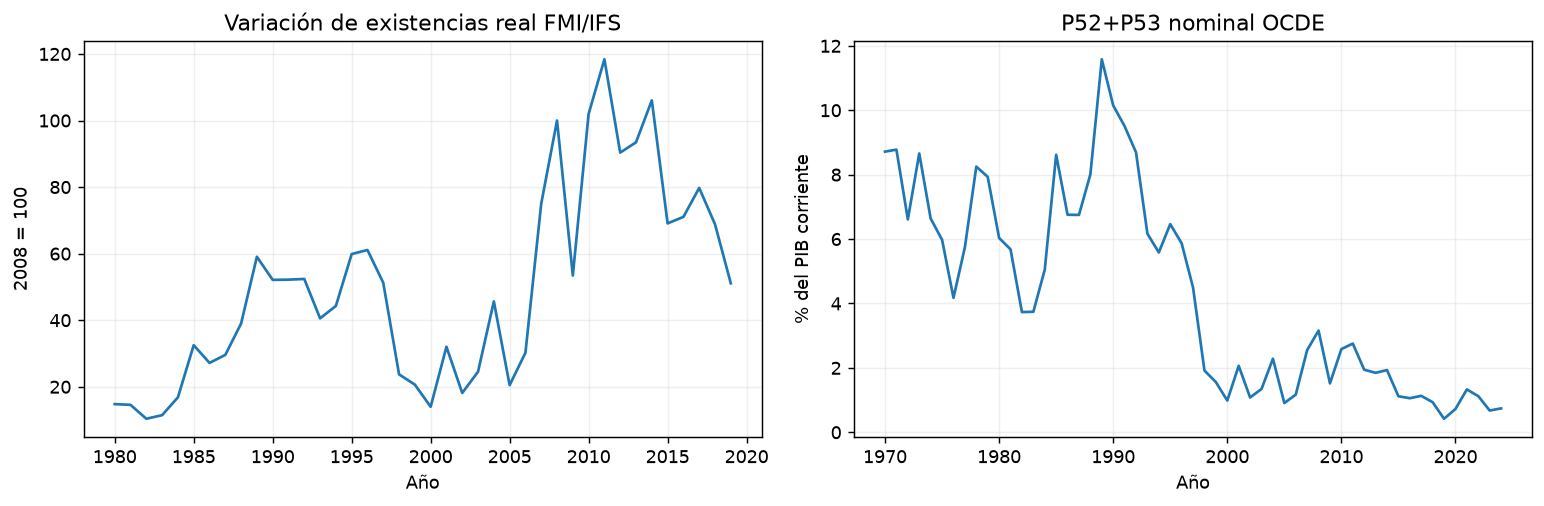

In [4]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
z=series('ALT.INVENTORIES_REAL_INDEX');axes[0].plot(z['year'],z['value']);axes[0].set(ylabel='2008 = 100',title='Variación de existencias real FMI/IFS',xlabel='Año')
z=series('SHARE.OECD.P5M');axes[1].plot(z['year'],z['value']);axes[1].set(ylabel='% del PIB corriente',title='P52+P53 nominal OCDE',xlabel='Año')
for ax in axes:ax.grid(alpha=.2)
show(fig,'03_existencias')

## Input-output: requerimientos intermedios por unidad de producción

Cada coeficiente es `flujo del sector i al sector j / producción bruta de j`. No es el peso del proveedor dentro de los consumos intermedios. La escala monetaria se cancela. Los niveles monetarios auxiliares usan una escala inferida por comparación con la tabla de flujos de fondos; los coeficientes no necesitan esa inferencia.

supplying_sector,using_sector,value,gross_output_using,technical_coefficient,year,bronze_sha256
str,str,f64,f64,f64,i64,str
"""agriculture""","""agriculture""",22600.7,159781.0,0.141448,2023,"""448c78055946ef02f3e26b6efc64e8…"
"""agriculture""","""industry""",61212.6,1.8359e6,0.033342,2023,"""448c78055946ef02f3e26b6efc64e8…"
"""agriculture""","""services""",17726.0,1385796.7,0.012791,2023,"""448c78055946ef02f3e26b6efc64e8…"
"""industry""","""agriculture""",31845.1,159781.0,0.199305,2023,"""448c78055946ef02f3e26b6efc64e8…"
"""industry""","""industry""",1025705.7,1.8359e6,0.558698,2023,"""448c78055946ef02f3e26b6efc64e8…"
"""industry""","""services""",213342.5,1385796.7,0.153949,2023,"""448c78055946ef02f3e26b6efc64e8…"
"""services""","""agriculture""",10102.5,159781.0,0.063227,2023,"""448c78055946ef02f3e26b6efc64e8…"
"""services""","""industry""",267178.4,1.8359e6,0.145531,2023,"""448c78055946ef02f3e26b6efc64e8…"
"""services""","""services""",430783.7,1385796.7,0.310856,2023,"""448c78055946ef02f3e26b6efc64e8…"


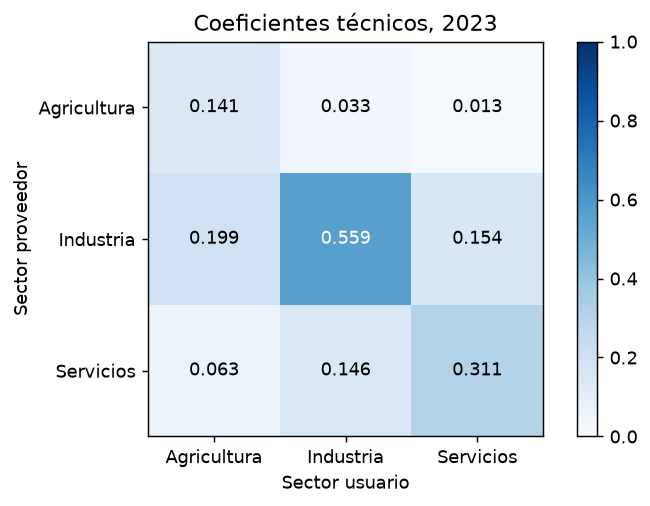

In [5]:
io=pl.read_csv(OUT/'io_2023_coeficientes_tecnicos.csv');display(io)
names=['agriculture','industry','services'];labels=['Agricultura','Industria','Servicios']
a=[[io.filter((pl.col('supplying_sector')==i)&(pl.col('using_sector')==j))['technical_coefficient'][0] for j in names] for i in names]
fig,ax=plt.subplots(figsize=(6,4));im=ax.imshow(a,cmap='Blues',vmin=0,vmax=1)
ax.set_xticks(range(3),labels);ax.set_yticks(range(3),labels)
for i in range(3):
    for j in range(3):ax.text(j,i,f'{a[i][j]:.3f}',ha='center',va='center',color='white' if a[i][j]>.5 else 'black')
ax.set(title='Coeficientes técnicos, 2023',xlabel='Sector usuario',ylabel='Sector proveedor');fig.colorbar(im,ax=ax)
show(fig,'04_io')

## Subvenciones: alternativa parcial y referencia reciente

NBS publica subvenciones a precios: 1978, 1980, 1985 y todos los años 1990–2006. Es una categoría fiscal parcial, con posibles ayudas a consumidores, y antes de 1986 se registraba como ingreso negativo. La estimación FMI de subvenciones monetarias a empresas no financieras es 2% del PIB en 2023; se conserva como dato aparte. Ninguna de las dos sustituye exactamente D3 de toda la economía. El Excel anual reciente del FMI está localizado pero su descarga devuelve 403.

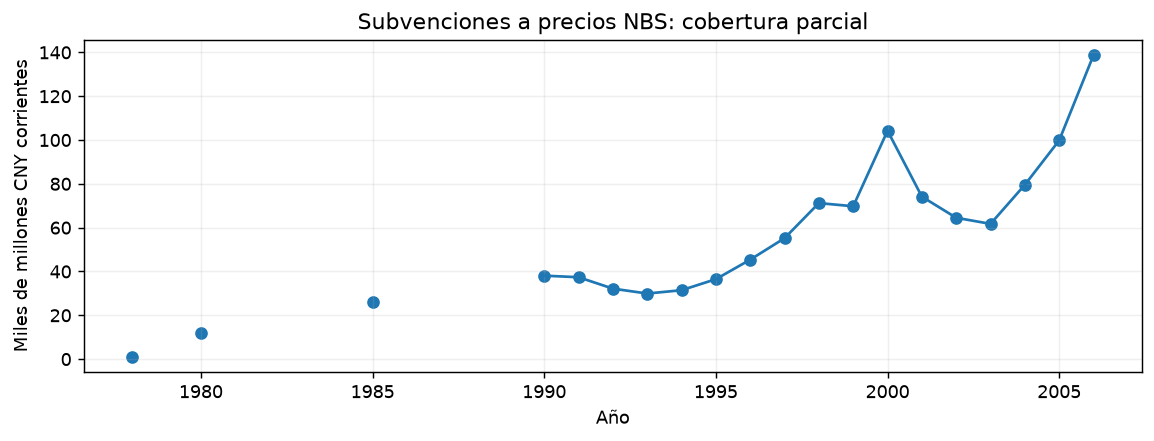

year,value,unit,quality
i64,f64,str,str
2023,2.0,"""percent_GDP""","""REFERENCIA_PUNTUAL_NO_D3"""


In [6]:
z=series('ALT.NBS.PRICE_SUBSIDIES')
fig,ax=plt.subplots(figsize=(9,3.5));ax.scatter(z['year'],z['value']/1000)
annual=z.filter(pl.col('year')>=1990);ax.plot(annual['year'],annual['value']/1000)
ax.set(xlabel='Año',ylabel='Miles de millones CNY corrientes',title='Subvenciones a precios NBS: cobertura parcial');ax.grid(alpha=.2)
show(fig,'05_subvenciones')
display(series('ALT.IMF.CASH_SUBSIDIES').select('year','value','unit','quality'))